In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv("Iris.csv")

In [3]:
X = df.iloc[:, :-1].values  # All columns except the last one
y = df.iloc[:, -1].values   # The last column (Target species)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [5]:
nb_classifier = GaussianNB()
nb_classifier.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[40.,40.,40.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.33,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U15](3,)","['Iris-setosa','Iris-versicolor','Iris-virginica']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.845e-06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 5)","[[ 25.43, 4.99, 3.4 , 1.48, 0.25], [ 77.05, 5.93, 2.75, 4.25, 1.32], [124.47, 6.61, 2.98, 5.58, 2.04]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 5)","[[215.39, 0.09, 0.16, 0.03, 0.01], [206.05, 0.22, 0.09, 0.19, 0.03], [205.45, 0.46, 0.12, 0.32, 0.07]]"


In [6]:
y_pred = nb_classifier.predict(X_test)

In [7]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Naive Bayes Model Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Naive Bayes Model Accuracy: 100.00%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



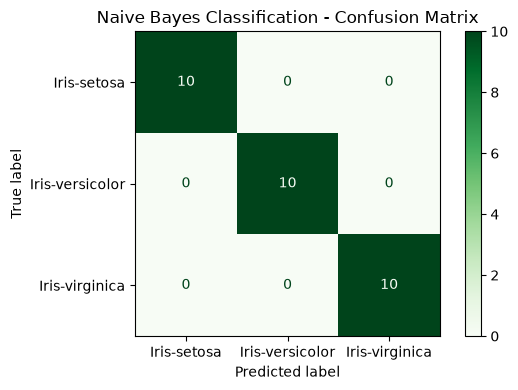

In [8]:
unique_labels = sorted(list(set(y)))
cm = confusion_matrix(y_test, y_pred, labels=unique_labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_labels)

# Render the plot with a Matplotlib color map
fig, ax = plt.subplots(figsize=(6, 4))
disp.plot(cmap=plt.cm.Greens, ax=ax)  # Using a green theme to distinguish it from the KNN plot

plt.title('Naive Bayes Classification - Confusion Matrix')
plt.tight_layout()

# Display the plot window
plt.show()